<a href="https://colab.research.google.com/github/perk-bevis/understanding-transformers/blob/main/transformel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [164]:
from transformers import pipeline

pipe = pipeline(
    "text-generation",
    model="openai-community/gpt2"
)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

In [165]:
prompt = "What is machine learning?"
result = pipe(prompt)
print(result)

[{'generated_text': "What is machine learning? I really don't know.\n\nWhy is machine learning important? Machine learning, in its very simplest form, is a way to learn how to live in a real world, from a computer's perspective. Machine learning is a way of understanding the world, how you think, what you need to do, and so on. It is possible to do all of these things in less than a millisecond, but there are many advantages to machine learning, and that is why I think machine learning as a discipline is so important.\n\nMachine learning is a way to learn how to live in a real world. Machine learning is a way of understanding the world, how you think, what you need to do, and so on.\n\nWhat can we learn from machine learning?\n\nOne thing that I think machine learning can learn from is how to be human. This is a good thing because it gives us a way to understand the world and do things that are not human. We are human, and we can choose to do things that are not human. We have to choos

In [166]:
print(result[0]["generated_text"])

What is machine learning? I really don't know.

Why is machine learning important? Machine learning, in its very simplest form, is a way to learn how to live in a real world, from a computer's perspective. Machine learning is a way of understanding the world, how you think, what you need to do, and so on. It is possible to do all of these things in less than a millisecond, but there are many advantages to machine learning, and that is why I think machine learning as a discipline is so important.

Machine learning is a way to learn how to live in a real world. Machine learning is a way of understanding the world, how you think, what you need to do, and so on.

What can we learn from machine learning?

One thing that I think machine learning can learn from is how to be human. This is a good thing because it gives us a way to understand the world and do things that are not human. We are human, and we can choose to do things that are not human. We have to choose to live in a world where we

In [167]:
from transformers import AutoTokenizer, AutoModelForCausalLM

tokenizer = AutoTokenizer.from_pretrained("openai-community/gpt2")
model = AutoModelForCausalLM.from_pretrained("openai-community/gpt2", device_map="auto")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

In [168]:
model


GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-11): 12 x GPT2Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=2304, nx=768)
          (c_proj): Conv1D(nf=768, nx=768)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=3072, nx=768)
          (c_proj): Conv1D(nf=768, nx=3072)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
  )
  (lm_head): Linear(in_features=768, out_features=50257, bias=False)
)

In [169]:
from transformers import AutoTokenizer
import torch
import torch.nn.functional as F

In [170]:
tokenizer = AutoTokenizer.from_pretrained("gpt2")

In [171]:
sentence = "unsure"
input_ids = tokenizer(sentence ,return_tensors="pt")["input_ids"]
input_ids

tensor([[13271,   495]])

In [172]:
tokenizer.decode(input_ids[0])


'unsure'

In [173]:
sentence = "unbelivable"
input_ids = tokenizer(sentence ,return_tensors="pt").input_ids
input_ids

tensor([[  403,  6667, 21911]])

In [174]:
for token_id in input_ids[0]:
    print(tokenizer.decode(token_id))

un
bel
ivable


In [175]:
word = "homoscedasticity"
my_ids = tokenizer(word, return_tensors="pt").input_ids
my_ids

tensor([[26452,   418,   771,  3477,   414]])

In [176]:
tokenizer.decode(my_ids.squeeze())

'homoscedasticity'

In [177]:
word = "pneumonoultramicroscopicsilicovolcanoconiosis"
my_ids = tokenizer(word, return_tensors="pt").input_ids
# len(my_ids[0])
my_ids

tensor([[   79, 25668,   261, 25955,   859,  2500,  1416,   404,   873, 41896,
           709,   349,  5171, 36221, 42960]])

In [178]:
for token_id in my_ids.squeeze():
    print(tokenizer.decode(token_id))

p
neum
on
oult
ram
icro
sc
op
ics
ilic
ov
ol
can
ocon
iosis


In [179]:
sentence = "antidisestablishmentarianism"
token_ids = tokenizer(sentence, return_tensors="pt").input_ids
token_ids, len(token_ids[0])

(tensor([[  415, 29207, 44390,  3699,  1042]]), 5)

In [180]:

word = "floccinaucinihilipilification"

my_ids = tokenizer(word, return_tensors="pt").input_ids
my_ids, len(my_ids[0])

(tensor([[ 2704, 13966,   259, 14272,   259, 20898,   541,   346,  2649]]), 9)

In [181]:

for token_id in my_ids[0]:
    print(tokenizer.decode(token_id))

fl
occ
in
auc
in
ihil
ip
il
ification


In [182]:
from transformers import AutoModelForCausalLM

In [183]:
gpt2 = AutoModelForCausalLM.from_pretrained("gpt2")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

In [184]:

gpt2

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-11): 12 x GPT2Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=2304, nx=768)
          (c_proj): Conv1D(nf=768, nx=768)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=3072, nx=768)
          (c_proj): Conv1D(nf=768, nx=3072)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
  )
  (lm_head): Linear(in_features=768, out_features=50257, bias=False)
)

In [185]:
sentence = "I like machine learning to be able to predict the future."
# Data Processing technique
token_ids = tokenizer(sentence, return_tensors="pt").input_ids

outputs = gpt2(token_ids).logits[0, -1]
tokenizer.decode(outputs.argmax())

'\n'

In [186]:

sentence = "I learn machine learning to enhance our understanding of the world around us."

token_ids = tokenizer(sentence, return_tensors="pt").input_ids

outputs = gpt2(token_ids).logits[0, -1]
tokenizer.decode(outputs.argmax())

'\n'

In [187]:
sentence = "I learn machine learning to enhance"
token_ids = tokenizer(sentence, return_tensors="pt").input_ids
outputs = gpt2(token_ids).logits[0, -1]
final_logits = torch.topk(outputs, 20) # Feel free to play around with the K

for index in final_logits.indices:
    print(tokenizer.decode(index))

 our
 the
 my
 your
 human
 a
 and
 its
 their
 performance
 learning
 user
 data
 social
 real
 understanding
 information
,
 intelligence
 people


In [188]:
torch.softmax(final_logits.values, dim=0).sum()

tensor(1., grad_fn=<SumBackward0>)

In [189]:
torch.softmax(final_logits.values, dim=0).sum()

tensor(1., grad_fn=<SumBackward0>)

In [190]:
def greedy_decode(logits):
    """Return token index with maximum probability."""
    return torch.argmax(logits, dim=-1)

# TOP K SAMPLING

def top_k_sampling(logits, k=50):
    """
    keeps only top-k logits, normalize them into probability.
    them sample one token from the filtered distribution.
    """
    values, indices = torch.topk(logits, k)
    probs = F.softmax(values, dim=-1)
    sampled = torch.multinomial(probs, 1)
    return indices[sampled]

# Top-p (Nuecles) Sampling

def top_p_sampling(logits, p=0.9):
    """
    Sort tokens by probability, keep smallest number whose culumative
    probability exceeds threshold p, then sample one token.
    """

    sorted_logits, sorted_indices = torch.sort(logits, descending=True)
    sorted_probs = F.softmax(sorted_logits, dim=-1)
    cumulative_probs = sorted_probs.cumsum(dim=-1)

    # Mask token outside nuclues
    mask = cumulative_probs > p
    sorted_logits[mask] = float("-inf")

    # Sample from filtered logits
    filtered_probs = F.softmax(sorted_logits, dim=-1)
    sampled = torch.multinomial(filtered_probs, 1)

    # Return token index in originial vocabulary
    return sorted_indices[sampled]

## Temperature Sampling ##

def temperature_sampling(logits, temperature=1.0):
    """
    Scale logits by temperature before sampling.
    Lower temperature => sharper distribution
    """

    scaled = logits / temperature
    probs = F.softmax(scaled, dim=-1)
    return torch.multinomial(probs, 1)


## Random Sampling ##

def random_sampling(logits):
    """
    Sample dirctly from softmax distribution without filtring
    """

    probs = F.softmax(logits, dim=-1)
    return torch.multinomial(probs, 1)

# sentence = "Today I decided to go to the local library and find out what was in my wallet."
sentence = "I am really happy becuase I have gone back in time."
inputs = tokenizer(sentence, return_tensors="pt")
output = gpt2(**inputs)
logits = output.logits[0, -1]

print(f"Greedy Decode: ", tokenizer.decode([greedy_decode(logits)]))
print(f"Top-K Sampling: ", tokenizer.decode(top_k_sampling(logits, k=10)))
print(f"Top-P-Sampling: ", tokenizer.decode(top_p_sampling(logits, p=0.9)))
print(f"Temp: ", tokenizer.decode(temperature_sampling(logits, temperature=1)))
print(f"Radnom: ", tokenizer.decode(random_sampling(logits)))

Greedy Decode:   I
Top-K Sampling:   I
Top-P-Sampling:   Now
Temp:   I
Radnom:   Thoughts


In [191]:
tokenizer.decode(top_k_sampling(outputs))

' or'

In [192]:
outputs

tensor([-109.4038, -108.0284, -114.4298,  ..., -111.9259, -117.0069,
        -109.9712], grad_fn=<SelectBackward0>)

In [193]:

tokenizer.decode(top_p_sampling(outputs, p=0.9))

' my'

In [194]:
tokenizer.decode(temperature_sampling(outputs, temperature=1.5))

' executions'

In [195]:
tokenizer.decode(random_sampling(outputs))

' my'

In [196]:
sentence = "I learn machine learning to enhance our understanding of the brain in"
token_ids = tokenizer(sentence, return_tensors="pt").input_ids
outputs = gpt2(token_ids).logits # Raw Unnormlized Score - Values
outputs = torch.softmax(outputs[0, -1], dim=-1)

top10 = torch.topk(outputs, k=10)

for index, value in zip(top10.indices, top10.values):
    print(f"{tokenizer.decode(index)} -- {value:.1%}")

 a -- 14.7%
 the -- 7.7%
 order -- 6.2%
 ways -- 6.2%
 general -- 4.5%
 humans -- 2.9%
 many -- 2.8%
 an -- 2.4%
 our -- 2.3%
 everyday -- 1.7%


In [197]:
# Load model directly
from transformers import AutoTokenizer, AutoModelForCausalLM

tokenizer = AutoTokenizer.from_pretrained("openai-community/gpt2")
model = AutoModelForCausalLM.from_pretrained("openai-community/gpt2")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

In [198]:
# Use a pipeline as a high-level helper
from transformers import pipeline

pipe = pipeline("text-generation", model="openai-community/gpt2")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

In [199]:

prompt = "What is machine learning?"
output = pipe(prompt)

In [200]:
print(output[0]["generated_text"])

What is machine learning?

Machine learning is a new field of research that uses computer programs and data to train our processes. It's a new field of research that uses algorithms to solve problems.

Machine learning is a new field of research that uses algorithms to solve problems. Machine learning is a new field of research that uses algorithms to solve problems. In the past, researchers have focused on machine learning and machine learning in the same category as problem solving.

Machine learning is a new field of research that uses algorithms to solve problems. Machine learning is a new field of research that uses algorithms to solve problems. In the past, researchers have focused on machine learning and machine learning in the same category as problem solving.

Machine learning is a new field of research that uses algorithms to solve problems. Machine learning is a new field of research that uses algorithms to solve problems. In the past, researchers have focused on machine lea

In [201]:
# Load model directly
from transformers import AutoTokenizer, AutoModelForCausalLM

tokenizer = AutoTokenizer.from_pretrained("openai-community/gpt2")
model = AutoModelForCausalLM.from_pretrained("openai-community/gpt2")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

In [202]:
model

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-11): 12 x GPT2Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=2304, nx=768)
          (c_proj): Conv1D(nf=768, nx=768)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=3072, nx=768)
          (c_proj): Conv1D(nf=768, nx=3072)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
  )
  (lm_head): Linear(in_features=768, out_features=50257, bias=False)
)

Sentiment Analysis

In [203]:
from datasets import load_dataset

ds = load_dataset("stanfordnlp/imdb")

In [204]:
type(ds)

datasets.dataset_dict.DatasetDict

In [205]:
ds

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})

In [206]:
ds["train"]

Dataset({
    features: ['text', 'label'],
    num_rows: 25000
})

In [207]:
import pandas as pd

In [208]:
ds["train"].to_pandas()

,text,label
0,I rented I AM CURIOUS-YELLOW from my video sto...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",0
2,If only to avoid making this type of film in t...,0
3,This film was probably inspired by Godard's Ma...,0
4,"Oh, brother...after hearing about this ridicul...",0
...,...,...
24995,A hit at the time but now better categorised a...,1
24996,I love this movie like no other. Another time ...,1
24997,This film and it's sequel Barry Mckenzie holds...,1
24998,'The Adventures Of Barry McKenzie' started lif...,1


In [209]:
my_dataset_df = ds["train"].to_pandas()

In [210]:
my_dataset_df["text"]

,text
0,I rented I AM CURIOUS-YELLOW from my video sto...
1,"""I Am Curious: Yellow"" is a risible and preten..."
2,If only to avoid making this type of film in t...
3,This film was probably inspired by Godard's Ma...
4,"Oh, brother...after hearing about this ridicul..."
...,...
24995,A hit at the time but now better categorised a...
24996,I love this movie like no other. Another time ...
24997,This film and it's sequel Barry Mckenzie holds...
24998,'The Adventures Of Barry McKenzie' started lif...


In [211]:
len(my_dataset_df["text"])

25000

In [212]:
from transformers import pipeline

In [213]:
classifier = pipeline("sentiment-analysis")

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

In [214]:
classifier("This day is great!")

[{'label': 'POSITIVE', 'score': 0.999881386756897}]

In [215]:
classifier("This day is terrible and i am so sad")[0]["label"]

'NEGATIVE'

In [216]:
def score(review_text):
    return classifier(review_text[:500])[0]["label"]

In [217]:
my_dataset_df["model_prediction"] = my_dataset_df["text"].apply(score)

In [218]:
my_dataset_df[["label", "model_prediction"]][:20]

,label,model_prediction
0,0,NEGATIVE
1,0,NEGATIVE
2,0,NEGATIVE
3,0,POSITIVE
4,0,NEGATIVE
5,0,NEGATIVE
6,0,NEGATIVE
7,0,NEGATIVE
8,0,NEGATIVE
9,0,NEGATIVE


In [219]:
my_dataset_df.iloc[0]

,0
text,I rented I AM CURIOUS-YELLOW from my video sto...
label,0
model_prediction,NEGATIVE


In [220]:
review = my_dataset_df.iloc[0]["text"]
classifier(review)[0]["label"]

'POSITIVE'

In [221]:
from transformers import pipeline

In [222]:
finbert = pipeline("sentiment-analysis", model="ProsusAI/finbert")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

In [223]:
sentence = "The company reported a strong increase in quarterly revnue, exceeding market expectations."
finbert(sentence)

[{'label': 'positive', 'score': 0.951565146446228}]

In [224]:
sentence = "Shares fell after the firm reported lower-than-expected earnings"
finbert(sentence)

[{'label': 'negative', 'score': 0.9718543887138367}]

In [225]:
sentences = ["Strong consumer demand drove record sales across all regions",
             "Supply chain disruptions severly affected production output"]

In [226]:
finbert(sentences)

[{'label': 'positive', 'score': 0.9434745907783508},
 {'label': 'negative', 'score': 0.9608097672462463}]

Named Entity Recognition

In [227]:
sentence = "Apple announced record earnings in the United States on Monday."

In [228]:
ner = pipeline("ner")

[transformers] No model was supplied, defaulted to dbmdz/bert-large-cased-finetuned-conll03-english and revision 4c53496.
Using a pipeline without specifying a model name and revision in production is not recommended.


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dbmdz/bert-large-cased-finetuned-conll03-english
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [229]:
sentence

'Apple announced record earnings in the United States on Monday.'

In [230]:
ner(sentence)

[{'entity': 'I-ORG',
  'score': np.float32(0.9991387),
  'index': 1,
  'word': 'Apple',
  'start': 0,
  'end': 5},
 {'entity': 'I-LOC',
  'score': np.float32(0.9997105),
  'index': 7,
  'word': 'United',
  'start': 39,
  'end': 45},
 {'entity': 'I-LOC',
  'score': np.float32(0.99967074),
  'index': 8,
  'word': 'States',
  'start': 46,
  'end': 52}]

In [231]:
sentence = "I live in UK worked at Facebook after graduating from Harvard"

In [232]:
ner(sentence)

[{'entity': 'I-LOC',
  'score': np.float32(0.9997962),
  'index': 4,
  'word': 'UK',
  'start': 10,
  'end': 12},
 {'entity': 'I-ORG',
  'score': np.float32(0.9983279),
  'index': 7,
  'word': 'Facebook',
  'start': 23,
  'end': 31},
 {'entity': 'I-ORG',
  'score': np.float32(0.9209187),
  'index': 11,
  'word': 'Harvard',
  'start': 54,
  'end': 61}]

**Question Answering**

In [233]:
import torch
from transformers import AutoTokenizer, AutoModelForQuestionAnswering

# 1. Tải tokenizer và model chuẩn của distilbert cho extractive QA
model_name = "distilbert/distilbert-base-uncased-distilled-squad"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForQuestionAnswering.from_pretrained(model_name)

# 2. Định nghĩa context và các câu hỏi
context = """
Financial sentiment analysis is a challenging task due to the specialized
language and lack of labeled data in that domain. General-purpose models are
not effective enough because of the specialized language used in a financial
context. We hypothesize that pre-trained language models can help with this
problem because they require fewer labeled examples and they can be further
trained on domain-specific corpora. We introduce FinBERT, a language model
based on BERT, to tackle NLP tasks in the financial domain. Our results show
improvement in every measured metric on current state-of-the-art results for
two financial sentiment analysis datasets. We find that even with a smaller
training set and fine-tuning only a part of the model, FinBERT outperforms
state-of-the-art machine learning methods.
"""

# Hàm phụ trợ giúp gọi nhanh gọn giống hệt cách cũ của bạn
def qa_bot(question, context):
    # Tokenize đầu vào gồm cả question và context
    inputs = tokenizer(question, context, return_tensors="pt")

    # Dự đoán vị trí bắt đầu và kết thúc của câu trả lời
    with torch.no_grad():
        outputs = model(**inputs)

    answer_start = torch.argmax(outputs.start_logits)
    answer_end = torch.argmax(outputs.end_logits) + 1

    # Cắt chuỗi token trả về câu trả lời chính xác
    answer = tokenizer.convert_tokens_to_string(
        tokenizer.convert_ids_to_tokens(inputs["input_ids"][0][answer_start:answer_end])
    )

    # Trả về dạng dictionary giống hệt pipeline cũ để bạn dùng result["answer"]
    return {"answer": answer}

# 3. Chạy thử nghiệm với các câu hỏi của bạn
question = "What is financial sentiment analysis?"
result = qa_bot(question=question, context=context)
print(result["answer"])

question = "What is FinBERT?"
result = qa_bot(question=question, context=context)
print(result["answer"])

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

a challenging task
a language model based on bert


**Machine** **Translation**

In [234]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

# 1. Tải tokenizer và model NLLB chuẩn trực tiếp (chỉ định rõ src_lang là tiếng Anh)
model_name = "facebook/nllb-200-distilled-600M"
tokenizer = AutoTokenizer.from_pretrained(model_name, src_lang="eng_Latn")
model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

# 2. Định nghĩa hàm dịch thuật đơn giản, gọn gàng
def translater(text):
    # Tokenize câu nguồn
    inputs = tokenizer(text, return_tensors="pt")

    # Dịch sang tiếng Pháp (fra_Latn)
    translated_tokens = model.generate(
        **inputs,
        forced_bos_token_id=tokenizer.convert_tokens_to_ids("fra_Latn"),
        max_length=50
    )

    # Giải mã token thành văn bản
    translated_text = tokenizer.decode(translated_tokens[0], skip_special_tokens=True)
    return translated_text

# 3. Chạy thử nghiệm các câu lệnh của bạn
print(translater("Hello"))
print(translater("Thanks"))

sentence = "What is your name?"
print(translater(sentence))

Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

Je vous salue .
Merci .
Comment vous appelez-vous ?


**audio processing using python**

In [235]:
import numpy as np
import matplotlib.pyplot as plt
import librosa

In [236]:

audio_path = "audio.mp3"
y, sr = librosa.load(audio_path)

In [237]:
y

array([0.00025094, 0.00028213, 0.00019896, ..., 0.0014153 , 0.00130616,
       0.00040388], dtype=float32)

In [238]:
y[:100]

array([ 2.5093951e-04,  2.8213154e-04,  1.9896177e-04,  1.5101006e-04,
        5.8936886e-05, -1.7069632e-04, -4.7867373e-04, -7.3832081e-04,
       -8.3403615e-04, -8.2674436e-04, -8.4082980e-04, -8.2562614e-04,
       -7.3050032e-04, -6.0832396e-04, -4.8463899e-04, -4.2319502e-04,
       -4.5133673e-04, -4.3832485e-04, -3.9548555e-04, -4.9832615e-04,
       -6.8613834e-04, -7.7582989e-04, -7.9931441e-04, -8.6572632e-04,
       -9.7776251e-04, -1.0772429e-03, -1.1465414e-03, -1.2982440e-03,
       -1.5856571e-03, -1.7763639e-03, -1.7024061e-03, -1.5696600e-03,
       -1.5436797e-03, -1.4985959e-03, -1.3792455e-03, -1.2861583e-03,
       -1.2200586e-03, -1.1489197e-03, -1.1465386e-03, -1.2504128e-03,
       -1.3732718e-03, -1.4082482e-03, -1.3469425e-03, -1.2767510e-03,
       -1.2162974e-03, -1.0912751e-03, -9.5056969e-04, -9.1160700e-04,
       -9.1240340e-04, -8.5790723e-04, -8.2171068e-04, -8.6497003e-04,
       -9.3751121e-04, -1.0059046e-03, -1.0516576e-03, -1.0531922e-03,
      

In [239]:
y.shape

(404177,)

In [240]:
sr

22050

Text(0, 0.5, 'amplitude')

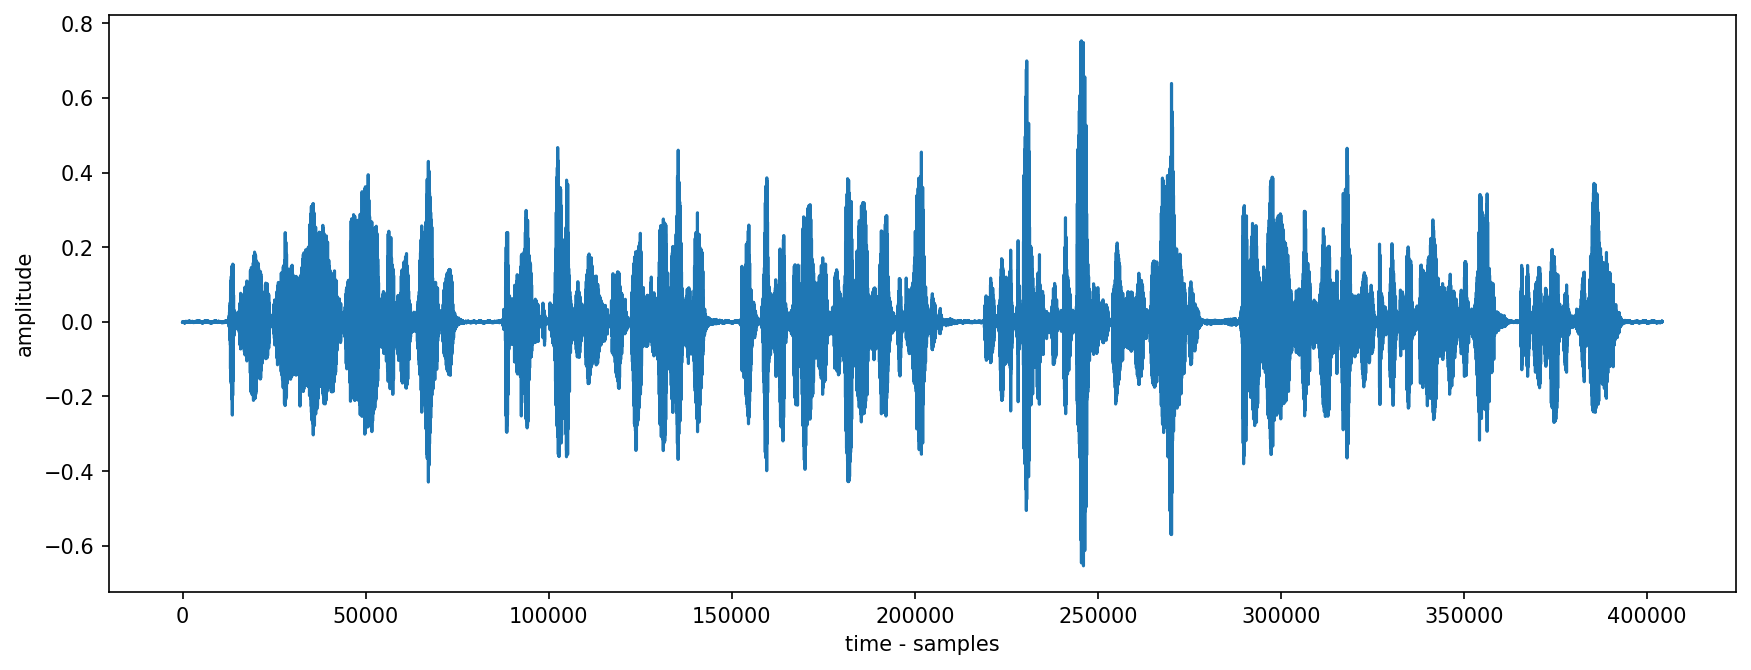

In [241]:
plt.figure(figsize=(14,5),dpi=150)
plt.plot(y)
plt.xlabel("time - samples")
plt.ylabel("amplitude")

In [242]:
import librosa

# Kiểm tra nếu chưa tải audio thì tải lại
try:
    y, sr
except NameError:
    audio_path = "audio.mp3"
    y, sr = librosa.load(audio_path)

len(y) / sr

18.330022675736963

In [243]:
from IPython.display import Audio

In [244]:
Audio(data=y, rate=sr)

In [245]:
# DFT - Discrete Fourier Transform
window = np.hanning(len(y))
windowed_input = y * window
dft = np.fft.rfft(windowed_input)

In [246]:
dft

array([-2.56692918e+01+0.00000000e+00j,  1.27908791e+01+1.82817401e-01j,
        2.18263641e-01-1.89370523e-02j, ...,
        1.86892604e-06-1.57246347e-06j, -2.10819903e-06+5.07785682e-06j,
        8.30450009e-07-1.09957312e-05j])

/usr/local/lib/python3.13/dist-packages/matplotlib/cbook.py:1709: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/usr/local/lib/python3.13/dist-packages/matplotlib/cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


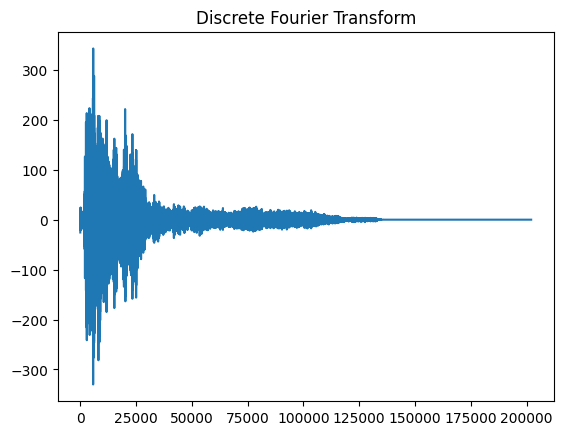

In [247]:
plt.plot(dft)
plt.title("Discrete Fourier Transform");

In [248]:
amplitude = np.abs(dft)

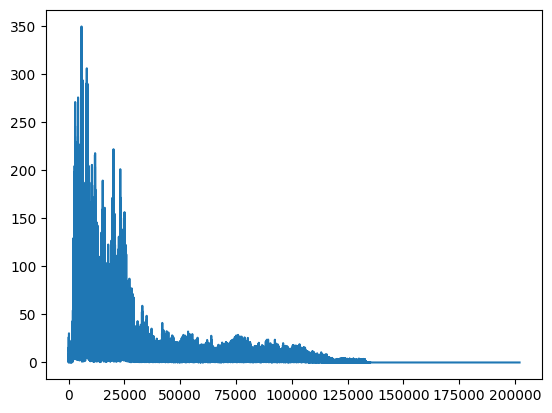

In [249]:
plt.plot(amplitude);

In [250]:
amplitude_db = librosa.amplitude_to_db(amplitude, ref=np.max)

In [251]:
frequency = librosa.fft_frequencies(sr=sr, n_fft=len(y))

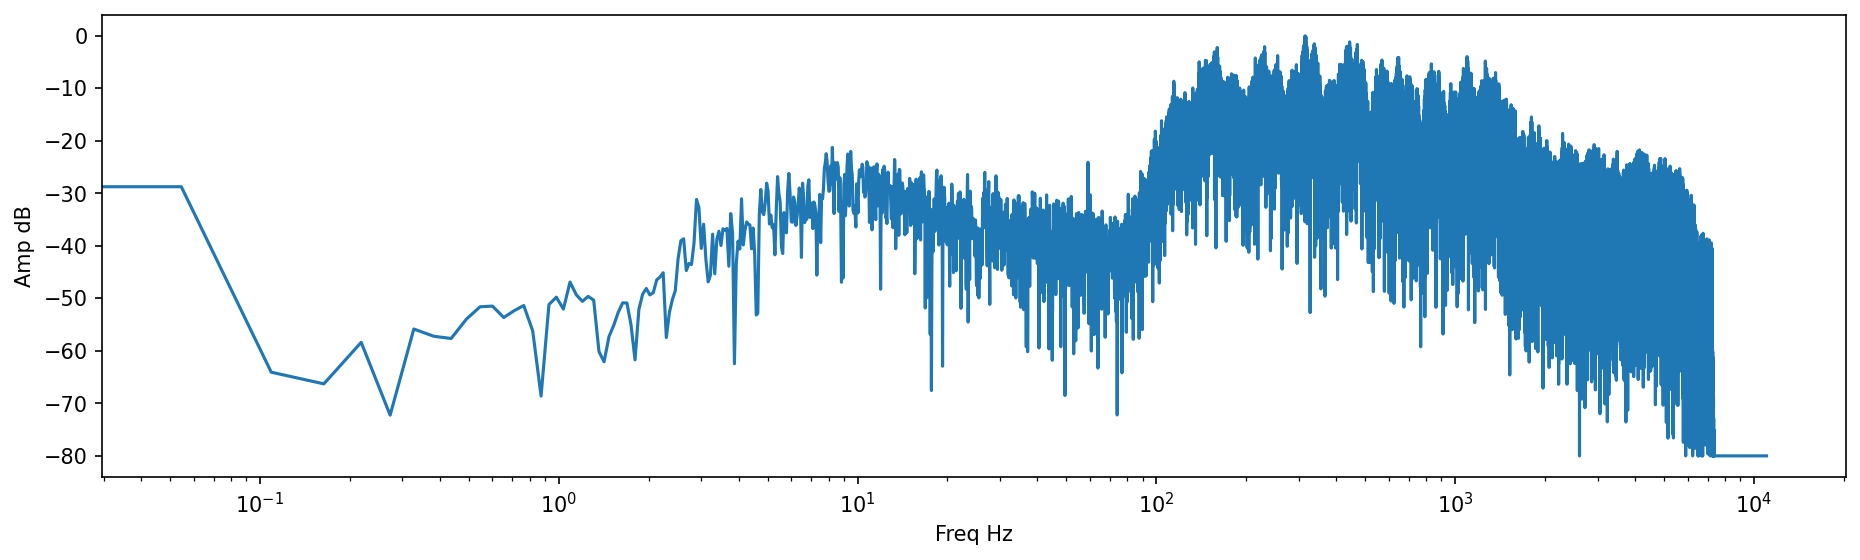

In [252]:
plt.figure(figsize=(15, 4), dpi=150)
plt.plot(frequency, amplitude_db)
plt.xlabel("Freq Hz")
plt.ylabel("Amp dB");
plt.xscale("log"); # logarithm

In [253]:

D = librosa.stft(y)
D

array([[-4.1237015e-01+0.00000000e+00j, -6.5538812e-01+0.00000000e+00j,
        -2.3858555e-01+0.00000000e+00j, ...,
        -7.8864455e-01+0.00000000e+00j, -6.3775367e-01+0.00000000e+00j,
        -2.6124898e-01+0.00000000e+00j],
       [ 1.5406418e-01-2.95892477e-01j,  5.4923260e-01+5.08327372e-02j,
         7.5689353e-02+3.57859522e-01j, ...,
         4.5061421e-01+8.75552222e-02j,  3.9504492e-01+6.42175749e-02j,
         7.6930858e-02+2.98652738e-01j],
       [ 1.0112785e-01+1.14491366e-01j, -3.3214542e-01-1.02588627e-02j,
         1.4470026e-01-8.13805610e-02j, ...,
        -1.8794512e-02-2.62098402e-01j, -1.2795874e-01+1.97091833e-01j,
         1.4762667e-01-2.45544329e-01j],
       ...,
       [ 8.7677712e-05-4.97421581e-07j, -4.3718916e-05+2.52073932e-07j,
         4.4785913e-09-1.13360732e-09j, ...,
        -7.6086126e-10+5.42066214e-09j,  4.6826626e-06+1.52645007e-05j,
        -2.0840313e-05-6.78983051e-05j],
       [-8.7673878e-05+2.50642785e-07j,  1.2752307e-07+4.37097988e-0

In [254]:
D_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)


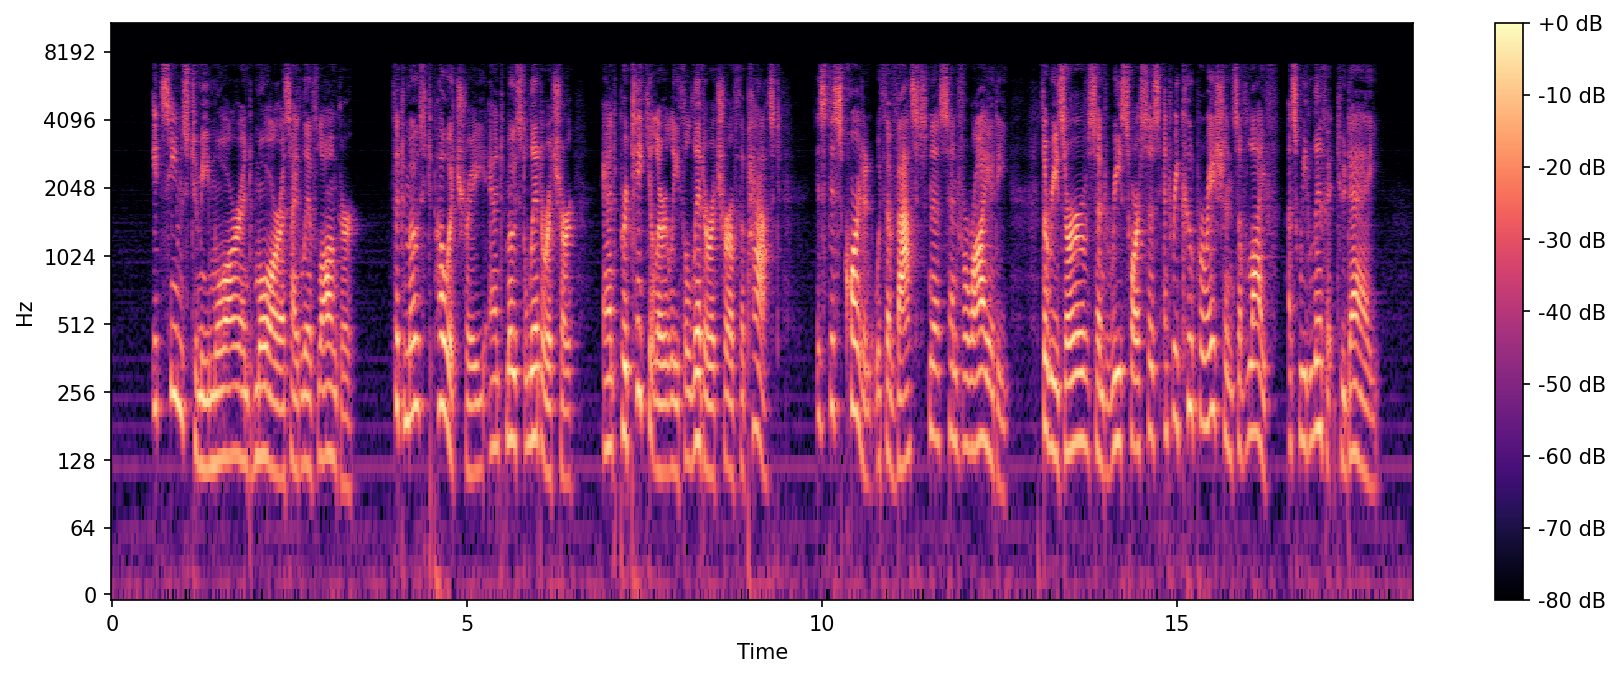

In [255]:
plt.figure(figsize=(14, 5), dpi=150)
librosa.display.specshow(D_db, sr=sr, x_axis="time", y_axis="log")
plt.colorbar(format="%+2.0f dB")

In [256]:
S = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128, fmax=8000)
S_dB = librosa.power_to_db(S, ref=np.max)

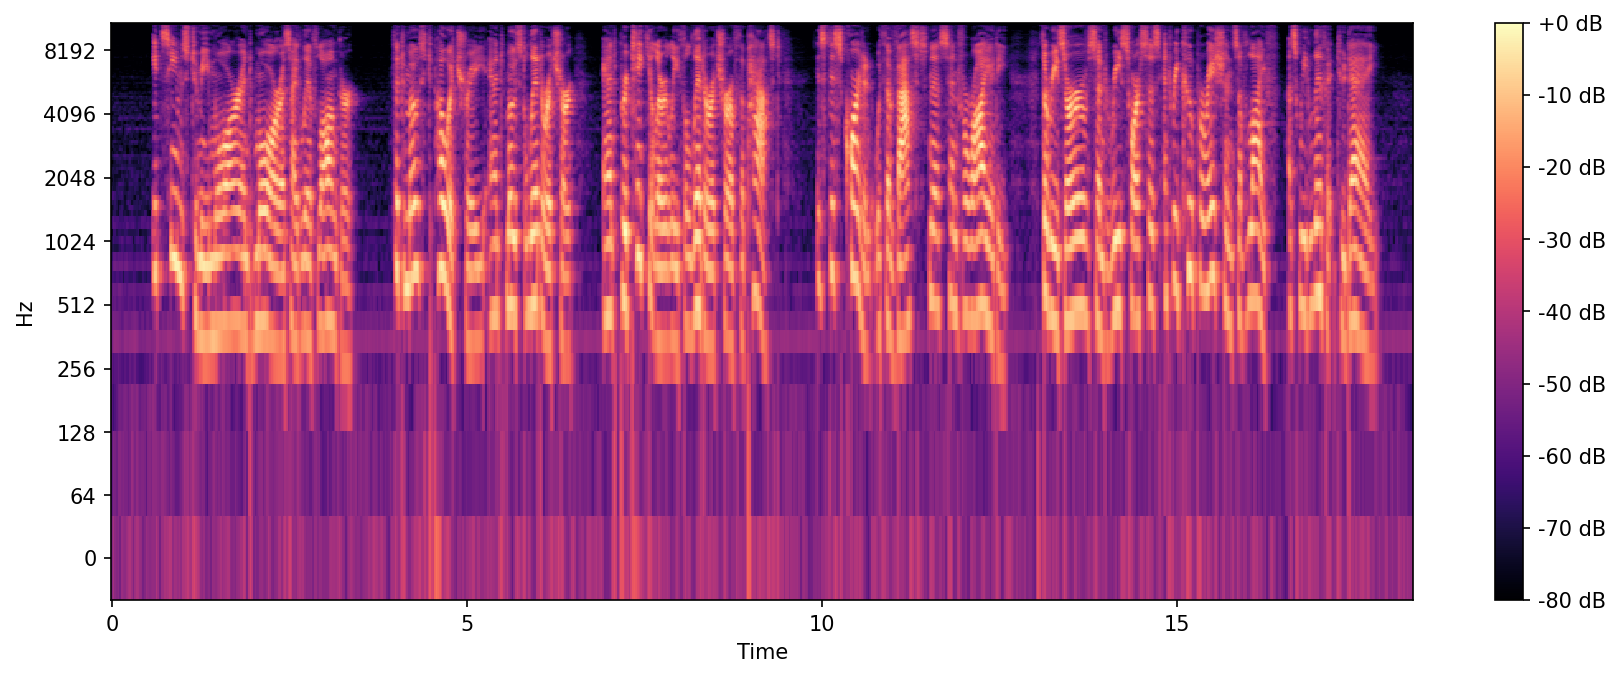

In [257]:
plt.figure(figsize=(14, 5), dpi=150)
librosa.display.specshow(S_dB, sr=sr, x_axis="time", y_axis="log", fmax=8000)
plt.colorbar(format="%+2.0f dB")

**Import required libraries - Audio Classification**

In [258]:
import torch, transformers, torchaudio
print(torch.__version__)
print(transformers.__version__)
print(torchaudio.__version__)

2.11.0+cu130
5.20.2
2.11.0+cu130


In [259]:
from transformers import AutoFeatureExtractor, ASTForAudioClassification

In [260]:
import librosa

In [261]:
audio_path = "audio.mp3"

In [262]:
y, sr = librosa.load(audio_path, sr=None)

In [263]:
y

array([0.00026489, 0.00024976, 0.00016459, ..., 0.00112344, 0.00131525,
       0.00124063], dtype=float32)

In [264]:
sr

16000

In [265]:
from IPython.display import Audio

In [266]:
Audio(data=audio_path)

In [267]:
feature_extractor = AutoFeatureExtractor.from_pretrained("MIT/ast-finetuned-audioset-10-10-0.4593")

In [268]:
result = feature_extractor(y, return_tensors="pt")

[transformers] It is strongly recommended to pass the `sampling_rate` argument to `ASTFeatureExtractor()`. Failing to do so can result in silent errors that might be hard to debug.


In [269]:
result["input_values"]

tensor([[[-0.9916, -1.2776, -1.0232,  ..., -1.2776, -1.2776, -1.2776],
         [-0.9121, -1.2776, -0.9703,  ..., -1.2776, -1.2776, -1.2776],
         [-0.8493, -1.2776, -0.9493,  ..., -1.2776, -1.2776, -1.2776],
         ...,
         [-0.9670, -1.2510, -0.8742,  ..., -1.1290, -1.2776, -1.2776],
         [-0.7404, -1.1572, -0.7803,  ..., -1.0399, -1.2776, -1.2776],
         [-1.2307, -1.2776, -1.0361,  ..., -1.1105, -1.2776, -1.2776]]])

In [270]:
model = ASTForAudioClassification.from_pretrained("MIT/ast-finetuned-audioset-10-10-0.4593")

Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

In [271]:
model

ASTForAudioClassification(
  (audio_spectrogram_transformer): ASTModel(
    (embeddings): ASTEmbeddings(
      (patch_embeddings): ASTPatchEmbeddings(
        (projection): Conv2d(1, 768, kernel_size=(16, 16), stride=(10, 10))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (layers): ModuleList(
      (0-11): 12 x ASTLayer(
        (attention): ASTAttention(
          (q_proj): Linear(in_features=768, out_features=768, bias=True)
          (k_proj): Linear(in_features=768, out_features=768, bias=True)
          (v_proj): Linear(in_features=768, out_features=768, bias=True)
          (o_proj): Linear(in_features=768, out_features=768, bias=True)
        )
        (layernorm_before): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
        (layernorm_after): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
        (mlp): ASTMLP(
          (activation_fn): GELUActivation()
          (fc1): Linear(in_features=768, out_features=3072, bias=True)
          (fc2): Li

In [272]:
result["input_values"]

tensor([[[-0.9916, -1.2776, -1.0232,  ..., -1.2776, -1.2776, -1.2776],
         [-0.9121, -1.2776, -0.9703,  ..., -1.2776, -1.2776, -1.2776],
         [-0.8493, -1.2776, -0.9493,  ..., -1.2776, -1.2776, -1.2776],
         ...,
         [-0.9670, -1.2510, -0.8742,  ..., -1.1290, -1.2776, -1.2776],
         [-0.7404, -1.1572, -0.7803,  ..., -1.0399, -1.2776, -1.2776],
         [-1.2307, -1.2776, -1.0361,  ..., -1.1105, -1.2776, -1.2776]]])

In [273]:
prediction_logits = model(result["input_values"]).logits

In [274]:
prediction_logits

tensor([[  1.7607,  -3.6278,  -5.1216,  -7.7976,  -4.6517,  -3.2460,  -9.5137,
          -3.6803, -10.1801,  -9.8109,  -9.2966, -10.5910, -12.0996, -11.3893,
         -10.0550,  -7.3453,  -8.1254,  -9.6309,  -9.5075,  -8.7204,  -9.9590,
          -7.4435,  -9.4690,  -9.6452,  -8.1356,  -9.9139,  -7.7653,  -9.1153,
         -11.2206, -11.5307, -10.7970,  -8.6758,  -9.5446, -10.2912, -10.9546,
         -12.5483,  -9.6943, -10.3114,  -9.3938, -10.0388,  -8.9071,  -5.2119,
          -7.9866,  -8.8267,  -4.6785,  -7.5004,  -6.4128,  -8.1301,  -6.1485,
          -7.9236,  -8.6372,  -8.1780,  -7.1531,  -7.5999,  -7.6198,  -7.0706,
         -10.8478,  -9.5550, -10.1405,  -8.3671,  -9.2931,  -7.4139,  -6.8052,
          -7.8090, -10.0894, -10.1416, -10.3179,  -9.5295, -11.4273,  -9.4677,
          -9.6600, -12.1333,  -5.2777,  -6.3861,  -7.1100,  -8.6034,  -9.1236,
         -11.6774,  -8.4648,  -9.2849,  -8.7651,  -6.6391,  -8.5326,  -7.7665,
          -7.1364,  -8.4690,  -8.9067,  -8.4986,  -8

In [275]:
predicted_class_ids = torch.argmax(prediction_logits, dim=-1).item()

In [276]:
predicted_class_ids

0

In [277]:
model.config.id2label

{0: 'Speech',
 1: 'Male speech, man speaking',
 2: 'Female speech, woman speaking',
 3: 'Child speech, kid speaking',
 4: 'Conversation',
 5: 'Narration, monologue',
 6: 'Babbling',
 7: 'Speech synthesizer',
 8: 'Shout',
 9: 'Bellow',
 10: 'Whoop',
 11: 'Yell',
 12: 'Battle cry',
 13: 'Children shouting',
 14: 'Screaming',
 15: 'Whispering',
 16: 'Laughter',
 17: 'Baby laughter',
 18: 'Giggle',
 19: 'Snicker',
 20: 'Belly laugh',
 21: 'Chuckle, chortle',
 22: 'Crying, sobbing',
 23: 'Baby cry, infant cry',
 24: 'Whimper',
 25: 'Wail, moan',
 26: 'Sigh',
 27: 'Singing',
 28: 'Choir',
 29: 'Yodeling',
 30: 'Chant',
 31: 'Mantra',
 32: 'Male singing',
 33: 'Female singing',
 34: 'Child singing',
 35: 'Synthetic singing',
 36: 'Rapping',
 37: 'Humming',
 38: 'Groan',
 39: 'Grunt',
 40: 'Whistling',
 41: 'Breathing',
 42: 'Wheeze',
 43: 'Snoring',
 44: 'Gasp',
 45: 'Pant',
 46: 'Snort',
 47: 'Cough',
 48: 'Throat clearing',
 49: 'Sneeze',
 50: 'Sniff',
 51: 'Run',
 52: 'Shuffle',
 53: 'Walk

In [278]:
model.config.id2label[predicted_class_ids]


'Speech'

**Converting Audio to Text**

In [279]:
from transformers import pipeline

In [280]:
pipe = pipeline("automatic-speech-recognition")

[transformers] No model was supplied, defaulted to facebook/wav2vec2-base-960h and revision 22aad52.
Using a pipeline without specifying a model name and revision in production is not recommended.


Loading weights:   0%|          | 0/212 [00:00<?, ?it/s]

[transformers] Wav2Vec2ForCTC LOAD REPORT from: facebook/wav2vec2-base-960h
Key                        | Status  | 
---------------------------+---------+-
wav2vec2.masked_spec_embed | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [281]:
pipe


AutomaticSpeechRecognitionPipeline: {'model': 'Wav2Vec2ForCTC', 'dtype': 'float32', 'device': 'cuda', 'input_modalities': 'audio'}

In [282]:
pipe("audio.mp3")

{'text': 'IT SEEMS TO ME MORE AND MORE AS I LIVE LONGER THAT MOST POETRY AND MOST LITERATURE AND PARTICULARLY THE LITERATURE OF THE PAST IS DISCORDANT WITH A VASTNESS AND VARIETY THE RESERVES AND RESOURCES AND RECUPERATIONS OF LIFE AS WE LIVE AT TO DAY'}

**Converting Text to Audio**

In [283]:
from transformers import pipeline
pipe = pipeline("text-to-speech")

[transformers] No model was supplied, defaulted to suno/bark-small and revision 1dbd7a1.
Using a pipeline without specifying a model name and revision in production is not recommended.


Loading weights:   0%|          | 0/542 [00:00<?, ?it/s]

In [284]:
text = "I like coding in python"

In [285]:
text


'I like coding in python'

In [286]:
output = pipe(text)

[transformers] Both `max_new_tokens` (=768) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/doc

In [287]:
output

{'audio': array([-0.00139306, -0.00125272, -0.00075704, ...,  0.00158219,
         0.00194239,  0.00354158], dtype=float32),
 'sampling_rate': 24000}

In [288]:
output["audio"]

array([-0.00139306, -0.00125272, -0.00075704, ...,  0.00158219,
        0.00194239,  0.00354158], dtype=float32)

In [289]:

output["audio"].shape

(125440,)

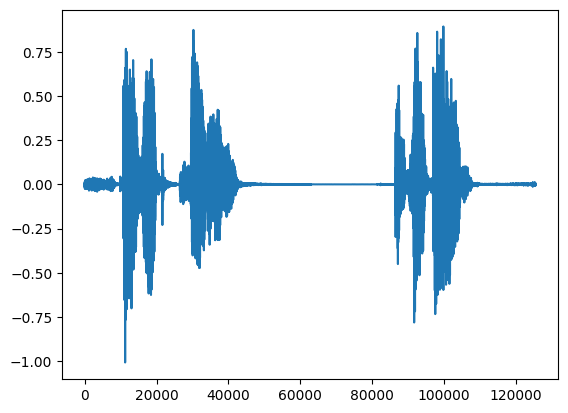

In [290]:
plt.plot(output["audio"].squeeze());

In [291]:
from IPython.display import Audio

In [292]:
Audio(data=output["audio"], rate=output["sampling_rate"])

In [293]:
from pydub import AudioSegment

In [294]:
audio_seg = AudioSegment(output["audio"].tobytes(),
                         frame_rate=output["sampling_rate"],
                         sample_width=output["audio"].dtype.itemsize,
                         channels=1)

In [295]:
audio_seg.export("my_audio_saved.mp3", format="mp3")

<_io.BufferedRandom name='my_audio_saved.mp3'>

**Image Processing Using Python**

In [296]:
from PIL import Image

In [297]:
pic = Image.open('white-flower.jpg')

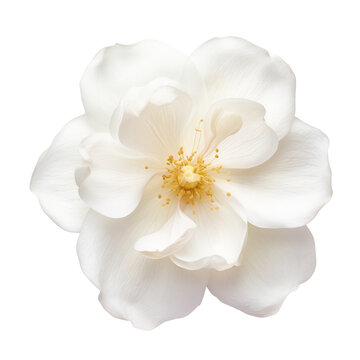

In [298]:
pic

In [299]:
type(pic)

PIL.JpegImagePlugin.JpegImageFile

In [300]:
import numpy as np

In [301]:
pic_arr = np.asarray(pic)

array([[[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       ...,

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]]], dtype=uint8)
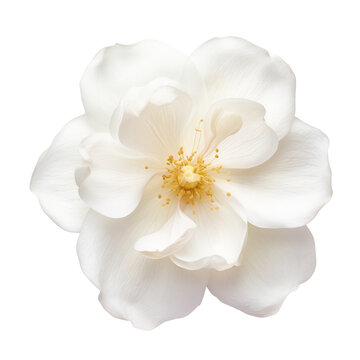

In [302]:
pic_arr

In [303]:
pic_arr.shape

(360, 360, 3)

In [304]:
pic_arr / 255

array([[[1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.],
        ...,
        [1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.]],

       [[1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.],
        ...,
        [1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.]],

       [[1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.],
        ...,
        [1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.]],

       ...,

       [[1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.],
        ...,
        [1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.]],

       [[1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.],
        ...,
        [1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.]],

       [[1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.],
        ...,
        [1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.]]])

In [305]:
import matplotlib.pyplot as plt

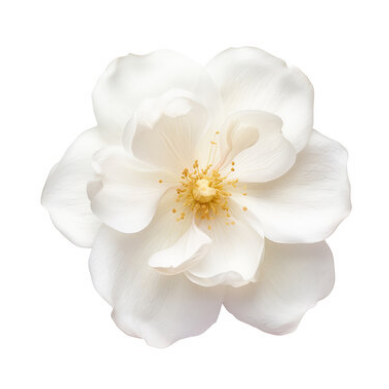

In [306]:
plt.imshow(pic_arr)
plt.axis(False);

In [307]:
pic_red = pic_arr.copy()

array([[[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       ...,

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]]], dtype=uint8)
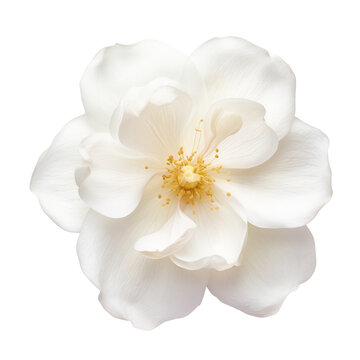

In [308]:
pic_red

In [309]:
# RGB

pic_red[:, :, 1] = 0 # GREEN Channel : set -> 0
pic_red[:, :, 2] = 0 # BLUE Channel : Set -> 0

array([[[255,   0,   0],
        [255,   0,   0],
        [255,   0,   0],
        ...,
        [255,   0,   0],
        [255,   0,   0],
        [255,   0,   0]],

       [[255,   0,   0],
        [255,   0,   0],
        [255,   0,   0],
        ...,
        [255,   0,   0],
        [255,   0,   0],
        [255,   0,   0]],

       [[255,   0,   0],
        [255,   0,   0],
        [255,   0,   0],
        ...,
        [255,   0,   0],
        [255,   0,   0],
        [255,   0,   0]],

       ...,

       [[255,   0,   0],
        [255,   0,   0],
        [255,   0,   0],
        ...,
        [255,   0,   0],
        [255,   0,   0],
        [255,   0,   0]],

       [[255,   0,   0],
        [255,   0,   0],
        [255,   0,   0],
        ...,
        [255,   0,   0],
        [255,   0,   0],
        [255,   0,   0]],

       [[255,   0,   0],
        [255,   0,   0],
        [255,   0,   0],
        ...,
        [255,   0,   0],
        [255,   0,   0],
        [255,   0,   0]]], dtype=uint8)
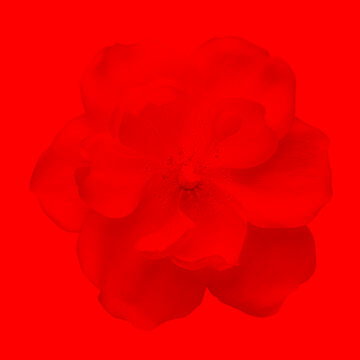

In [310]:
pic_red

array([[[  0, 255,   0],
        [  0, 255,   0],
        [  0, 255,   0],
        ...,
        [  0, 255,   0],
        [  0, 255,   0],
        [  0, 255,   0]],

       [[  0, 255,   0],
        [  0, 255,   0],
        [  0, 255,   0],
        ...,
        [  0, 255,   0],
        [  0, 255,   0],
        [  0, 255,   0]],

       [[  0, 255,   0],
        [  0, 255,   0],
        [  0, 255,   0],
        ...,
        [  0, 255,   0],
        [  0, 255,   0],
        [  0, 255,   0]],

       ...,

       [[  0, 255,   0],
        [  0, 255,   0],
        [  0, 255,   0],
        ...,
        [  0, 255,   0],
        [  0, 255,   0],
        [  0, 255,   0]],

       [[  0, 255,   0],
        [  0, 255,   0],
        [  0, 255,   0],
        ...,
        [  0, 255,   0],
        [  0, 255,   0],
        [  0, 255,   0]],

       [[  0, 255,   0],
        [  0, 255,   0],
        [  0, 255,   0],
        ...,
        [  0, 255,   0],
        [  0, 255,   0],
        [  0, 255,   0]]], dtype=uint8)
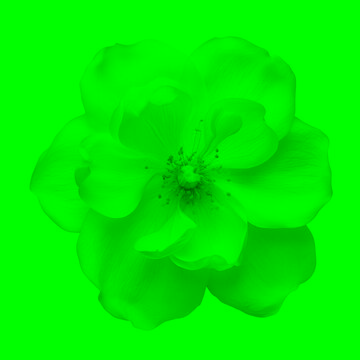

In [311]:
# RGB

pic_green = pic_arr.copy()
pic_green[:, :, 0] = 0 # Red channel is zeroed -> 0
pic_green[:, :, 2] = 0 # BLUE channel is zeroed -> 0

pic_green

array([[[  0,   0, 255],
        [  0,   0, 255],
        [  0,   0, 255],
        ...,
        [  0,   0, 255],
        [  0,   0, 255],
        [  0,   0, 255]],

       [[  0,   0, 255],
        [  0,   0, 255],
        [  0,   0, 255],
        ...,
        [  0,   0, 255],
        [  0,   0, 255],
        [  0,   0, 255]],

       [[  0,   0, 255],
        [  0,   0, 255],
        [  0,   0, 255],
        ...,
        [  0,   0, 255],
        [  0,   0, 255],
        [  0,   0, 255]],

       ...,

       [[  0,   0, 255],
        [  0,   0, 255],
        [  0,   0, 255],
        ...,
        [  0,   0, 255],
        [  0,   0, 255],
        [  0,   0, 255]],

       [[  0,   0, 255],
        [  0,   0, 255],
        [  0,   0, 255],
        ...,
        [  0,   0, 255],
        [  0,   0, 255],
        [  0,   0, 255]],

       [[  0,   0, 255],
        [  0,   0, 255],
        [  0,   0, 255],
        ...,
        [  0,   0, 255],
        [  0,   0, 255],
        [  0,   0, 255]]], dtype=uint8)
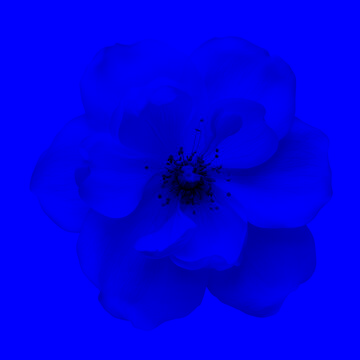

In [312]:
pic_blue = pic_arr.copy()

pic_blue[:, :, 0] = 0
pic_blue[:, :, 1] = 0
pic_blue

In [313]:
import cv2

In [314]:
img = cv2.imread("/content/white-flower.jpg")

array([[[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       ...,

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]]], dtype=uint8)
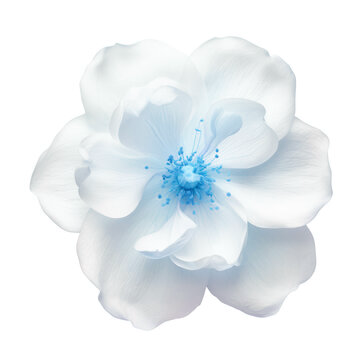

In [315]:
img

In [316]:
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

array([[[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       ...,

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]]], dtype=uint8)
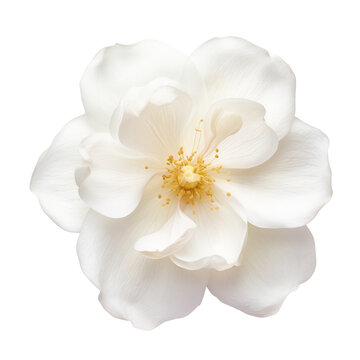

In [317]:
img_rgb

In [318]:
img_gray = cv2.imread("/content/white-flower.jpg", cv2.IMREAD_GRAYSCALE)

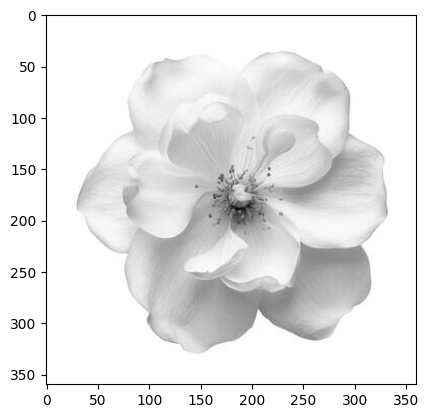

In [319]:
plt.imshow(img_gray, cmap="gray")

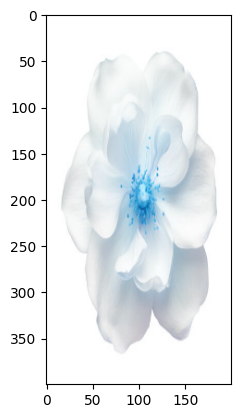

In [320]:
img_resize = cv2.resize(img, (200, 400))
plt.imshow(img_resize)

In [321]:
w_ratio = 0.5
h_ratio = 0.5

new_img = cv2.resize(img, (0, 0), fx=w_ratio, fy=h_ratio)

array([[[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       ...,

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]]], dtype=uint8)
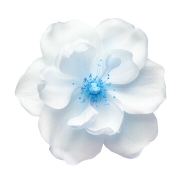

In [322]:
new_img

**Generating Faces using Diffusion Models**

In [3]:
import importlib.util

print("torchao:", importlib.util.find_spec("torchao"))

torchao: ModuleSpec(name='torchao', loader=<_frozen_importlib_external.SourceFileLoader object at 0x791955123e90>, origin='/usr/local/lib/python3.13/dist-packages/torchao/__init__.py', submodule_search_locations=['/usr/local/lib/python3.13/dist-packages/torchao'])


In [4]:
from diffusers import DDPMPipeline # Denoising Diffusion Probabilistic Model

Unable to import `torchao` Tensor objects. This may affect loading checkpoints serialized with `torchao`


In [5]:
ddpm = DDPMPipeline.from_pretrained("google/ddpm-celebahq-256").to("cuda")

model_index.json:   0%|          | 0.00/180 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/2 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--google--ddpm-celebahq-256/snapshots/cd5c944777ea2668051904ead6cc120739b86c4d: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--google--ddpm-celebahq-256/snapshots/cd5c944777ea2668051904ead6cc120739b86c4d.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


In [7]:
image = ddpm(num_inference_steps=30).images[0]

  0%|          | 0/30 [00:00<?, ?it/s]

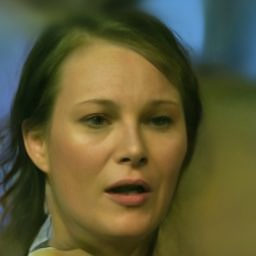

In [8]:
image

In [9]:
from diffusers import DDPMScheduler, UNet2DModel


In [10]:
scheduler = DDPMScheduler.from_pretrained("google/ddpm-celebahq-256")


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


In [11]:
scheduler

DDPMScheduler {
  "_class_name": "DDPMScheduler",
  "_diffusers_version": "0.42.0",
  "beta_end": 0.02,
  "beta_schedule": "linear",
  "beta_start": 0.0001,
  "clip_sample": true,
  "clip_sample_range": 1.0,
  "dynamic_thresholding_ratio": 0.995,
  "num_train_timesteps": 1000,
  "prediction_type": "epsilon",
  "rescale_betas_zero_snr": false,
  "sample_max_value": 1.0,
  "steps_offset": 0,
  "thresholding": false,
  "timestep_spacing": "leading",
  "trained_betas": null,
  "variance_type": "fixed_small"
}

In [12]:
model = UNet2DModel.from_pretrained("google/ddpm-celebahq-256").to("cuda")


An error occurred while trying to fetch google/ddpm-celebahq-256: google/ddpm-celebahq-256 does not appear to have a file named diffusion_pytorch_model.safetensors.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


In [13]:
model

UNet2DModel(
  (conv_in): Conv2d(3, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (time_proj): Timesteps()
  (time_embedding): TimestepEmbedding(
    (linear_1): Linear(in_features=128, out_features=512, bias=True)
    (act): SiLU()
    (linear_2): Linear(in_features=512, out_features=512, bias=True)
  )
  (down_blocks): ModuleList(
    (0-1): 2 x DownBlock2D(
      (resnets): ModuleList(
        (0-1): 2 x ResnetBlock2D(
          (norm1): GroupNorm(32, 128, eps=1e-06, affine=True)
          (conv1): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (time_emb_proj): Linear(in_features=512, out_features=128, bias=True)
          (norm2): GroupNorm(32, 128, eps=1e-06, affine=True)
          (dropout): Dropout(p=0.0, inplace=False)
          (conv2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (nonlinearity): SiLU()
        )
      )
      (downsamplers): ModuleList(
        (0): Downsample2D(
          (conv): Con

In [14]:
scheduler.set_timesteps(50)


In [15]:
scheduler.timesteps

tensor([980, 960, 940, 920, 900, 880, 860, 840, 820, 800, 780, 760, 740, 720,
        700, 680, 660, 640, 620, 600, 580, 560, 540, 520, 500, 480, 460, 440,
        420, 400, 380, 360, 340, 320, 300, 280, 260, 240, 220, 200, 180, 160,
        140, 120, 100,  80,  60,  40,  20,   0])

In [16]:
import torch

In [17]:
sample_size = model.config.sample_size

In [18]:
sample_size

256

In [19]:
noise = torch.randn((1, 3, sample_size, sample_size), device="cuda")


In [20]:
noise

tensor([[[[ 1.0878, -0.5777, -0.8856,  ...,  0.0452,  2.3746,  0.6513],
          [ 0.0717,  0.3769, -0.4594,  ...,  0.2119,  0.0281,  0.8769],
          [ 0.0913, -0.0463, -0.6962,  ..., -1.0710, -1.8507, -0.8178],
          ...,
          [ 0.3241,  0.8573, -0.5032,  ..., -0.2513, -0.6235,  0.7784],
          [-1.1990, -0.7288, -1.5309,  ...,  1.1692,  1.8005, -0.8650],
          [ 1.0830,  1.1036,  0.1628,  ...,  1.3467,  1.4417, -0.9853]],

         [[-0.0783,  0.6938, -0.1337,  ...,  0.1122, -1.2070,  0.3865],
          [ 0.8214, -0.2766,  0.6854,  ..., -0.2235,  0.3203,  0.3607],
          [-0.7897,  0.4577,  0.0527,  ...,  0.1494, -0.5324, -0.1865],
          ...,
          [ 0.0499, -0.1096,  2.2905,  ..., -1.2831, -0.4834, -0.0671],
          [ 0.4602, -0.1539,  1.2448,  ...,  1.3530,  0.2604,  1.3646],
          [ 0.2468, -0.2196,  0.8636,  ...,  1.4751,  1.4246, -0.1130]],

         [[-0.9176,  0.3200, -0.4275,  ...,  1.2991,  2.8051,  0.1441],
          [-1.4883, -0.1919,  

In [22]:
import matplotlib.pyplot as plt

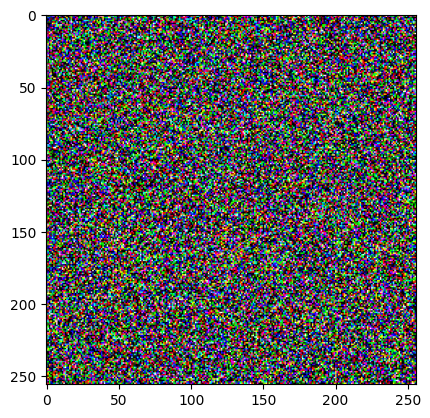

In [23]:
input = noise
plt.imshow(input.squeeze().permute(1, 2, 0).detach().to("cpu").numpy());

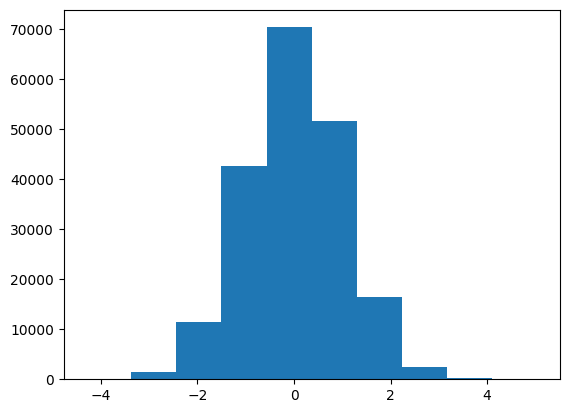

In [24]:
plt.hist(input.squeeze().permute(1, 2, 0).detach().to("cpu").numpy().flatten());

In [25]:
scheduler.timesteps, len(scheduler.timesteps)

(tensor([980, 960, 940, 920, 900, 880, 860, 840, 820, 800, 780, 760, 740, 720,
         700, 680, 660, 640, 620, 600, 580, 560, 540, 520, 500, 480, 460, 440,
         420, 400, 380, 360, 340, 320, 300, 280, 260, 240, 220, 200, 180, 160,
         140, 120, 100,  80,  60,  40,  20,   0]),
 50)

In [26]:
for t in scheduler.timesteps:
    with torch.inference_mode(): # enable and turn on inference mode
        noisy_residual = model(input, t).sample

        previous_noisy_sample = scheduler.step(noisy_residual, t, input).prev_sample

        input = previous_noisy_sample

In [27]:
from PIL import Image
import numpy as np

In [28]:
image = (input / 2 + 0.5).clamp(0, 1).squeeze()

In [29]:
image = (image.permute(1, 2, 0) * 255).round().to(torch.uint8).cpu().numpy()

In [30]:
image = Image.fromarray(image)

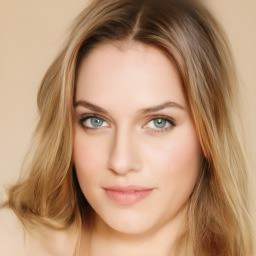

In [31]:
image

**Generating Images using a prompt with Diffusion Models**

In [32]:
import torch
from diffusers import DiffusionPipeline

# switch to "mps" for apple devices
pipe = DiffusionPipeline.from_pretrained("stabilityai/stable-diffusion-xl-base-1.0", dtype=torch.bfloat16, device_map="cuda")

prompt = "Astronaut in a jungle, cold color palette, muted colors, detailed, 8k"
image = pipe(prompt).images[0]

model_index.json:   0%|          | 0.00/609 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 19 files:   0%|          | 0/19 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
image

In [ ]:
prompt = "a cute and adorable bunny, with huge clear eyes, holding a bunch of flowers, in the style of cute pixar character"
image = pipe(prompt).images[0]
image

In [ ]:
prompt = "a cute and lovely 4-year-old baby girl with a magical power, cosmic energy, lovely smile, digital painting, hyperrealistic, highly detailed, sharp, masterpiece"
image = pipe(prompt).images[0]
image

In [ ]:
prompt = "A giraffe with top hat" # [A] [Giraffe] [with] => [0.5, 0.3, 0.2]
image = pipe(prompt).images[0]
image

**Video Models**

In [ ]:
import torch
import diffusers
import transformers
import cv2

**Generating Video With Diffusion**

In [ ]:
from diffusers import StableVideoDiffusionPipeline

In [ ]:
pipe = StableVideoDiffusionPipeline.from_pretrained("stabilityai/stable-video-diffusion-img2vid-xt",
                                                    torch_dtype=torch.float16,
                                                    variant="fp16")


In [ ]:
pipe

In [ ]:
path = "elmo.jpg"

In [ ]:
path

In [ ]:
from diffusers.utils import load_image, export_to_video

In [ ]:
image = load_image(path)

In [ ]:
image

In [ ]:
pipe.enable_model_cpu_offload()


In [ ]:
generator = torch.manual_seed(42)

In [ ]:
generator

In [ ]:
image